In [1]:
import os
import cv2
import numpy as np
import shutil
from tqdm import tqdm

def analyze_mask_geometry(mask):
 

    _, binary_mask = cv2.threshold(mask, 127, 255, cv2.THRESH_BINARY)
  
    area = np.sum(binary_mask == 255)
   
    if area < 10: 
        return {"is_anomalous": True, "reason": "Zero/Tiny Area", "solidity": 0.0}
    contours, _ = cv2.findContours(binary_mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        c = max(contours, key=cv2.contourArea)
        hull = cv2.convexHull(c)
        hull_area = cv2.contourArea(hull)
        
        if hull_area > 0:
            solidity = float(cv2.contourArea(c)) / hull_area
        else:
            solidity = 0.0
            
        if solidity < 0.3:
            return {"is_anomalous": True, "reason": "Low Solidity (Fractured)", "solidity": solidity}
            
    return {"is_anomalous": False, "reason": "Valid Geometry", "solidity": 1.0}

def calculate_iou(mask_gt, mask_pred):

    gt = (mask_gt > 127).astype(np.uint8)
    pred = (mask_pred > 127).astype(np.uint8)
    
    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    
    if union == 0:
        return 1.0
    return intersection / union




IMAGE_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/"
MASK_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/"
OUTPUT_ERR_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/error-images/data_center_2"

os.makedirs(OUTPUT_ERR_DIR, exist_ok=True)


report = {"Valid": 0, "Zero/Tiny Area": 0, "Low Solidity (Fractured)": 0}

print("Data quality on go..")

for mask_name in tqdm(os.listdir(MASK_DIR)):
    mask_path = os.path.join(MASK_DIR, mask_name)
    image_path = os.path.join(IMAGE_DIR, mask_name.replace(".png", ".jpg")) 
    
 
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        continue
        

    geo_status = analyze_mask_geometry(mask)
    
    if geo_status["is_anomalous"]:
        reason = geo_status["reason"]
        report[reason] += 1
        
        reason_folder = os.path.join(OUTPUT_ERR_DIR, reason.replace(" ", "_").lower())
        os.makedirs(reason_folder, exist_ok=True)
        
        shutil.copy(mask_path, os.path.join(reason_folder, f"mask_{mask_name}"))
        if os.path.exists(image_path):
            shutil.copy(image_path, os.path.join(reason_folder, f"img_{mask_name.replace('.png', '.jpg')}"))
    else:
        report["Valid"] += 1

print("Final data presentation")
total_processed = sum(report.values())
for key, value in report.items():
    percentage = (value / total_processed) * 100
    print(f"🔹 {key}: {value} images ({percentage:.2f}%)")

Data quality on go..


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 301/301 [00:06<00:00, 45.05it/s]

Final data presentation
🔹 Valid: 269 images (89.37%)
🔹 Zero/Tiny Area: 32 images (10.63%)
🔹 Low Solidity (Fractured): 0 images (0.00%)


In [10]:
import os
import cv2
import numpy as np
import tensorflow as tf
import shutil
from tqdm import tqdm

# `tf.keras.saving` doesn't exist on every TF/Keras combo (depends on whether
# you're on standalone Keras 3, or TF's bundled keras, or the legacy
# tf_keras compat shim). Import `keras` directly and fall back gracefully.
try:
    import keras
    register_keras_serializable = keras.saving.register_keras_serializable
except AttributeError:
    # Older Keras (2.x style) exposes it under keras.utils instead
    register_keras_serializable = keras.utils.register_keras_serializable

# =========================================================================
# 0. CUSTOM OBJECTS REQUIRED FOR MODEL DESERIALIZATION
# =========================================================================
# IMPORTANT: This MUST be the exact same class definition used when you
# originally built/trained the model. If your training script defines
# KerasPCCLayer differently, copy-paste the REAL definition here (or import
# it from your training module) instead of this one -- the *math* inside
# the layer has to match exactly, otherwise inference results will be wrong
# even though the file "loads" successfully.
#
# Recommended safer approach: instead of redefining it here, do:
#   import sys
#   sys.path.append("/path/to/folder/containing/your/training/script")
#   from your_training_script import KerasPCCLayer
# and delete the class below.

@register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    """
    Pearson Correlation Coefficient self-correlation layer.
    Computes pairwise PCC across the feature dimension of the input.
    Replace this body with your real implementation if it differs.
    """
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, inputs):
        # inputs: [batch, features]
        x = inputs - tf.reduce_mean(inputs, axis=-1, keepdims=True)
        x = x / (tf.math.reduce_std(inputs, axis=-1, keepdims=True) + 1e-8)
        # Pairwise correlation matrix per sample, flattened
        corr = tf.matmul(x[:, :, None], x[:, None, :]) / tf.cast(tf.shape(inputs)[-1], tf.float32)
        return tf.reshape(corr, (tf.shape(inputs)[0], -1))

    def get_config(self):
        return super().get_config()


CUSTOM_OBJECTS = {
    "KerasPCCLayer": KerasPCCLayer,
}

# =========================================================================
# 1. MODEL LOADING CONFIGURATION
# =========================================================================
def load_my_segmentation_model(checkpoint_path):
    """
    Loads the native Keras segmentation model checkpoint for INFERENCE ONLY.
    compile=False skips reconstructing the optimizer/loss/metrics (which is
    what was actually throwing the error), so we only need custom_objects
    for layers that are part of the model's forward graph.
    """
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"⚠️ Model checkpoint not found at: {checkpoint_path}")

    model = tf.keras.models.load_model(
        checkpoint_path,
        custom_objects=CUSTOM_OBJECTS,
        compile=False,
    )
    print(f"✅ Model successfully loaded from: {checkpoint_path}")
    return model

# =========================================================================
# 2. CORE MATHEMATICAL & SPATIAL FILTER LOGIC
# =========================================================================
def check_spatial_mismatch(mask_gt, mask_pred, dist_threshold=80, iou_threshold=0.1):
    """
    Calculates the spatial distance between centroids of the Ground Truth
    and Predicted masks, along with their IoU score to detect label shifts.
    """
    gt = (mask_gt > 127).astype(np.uint8)
    pred = (mask_pred > 127).astype(np.uint8)

    if np.sum(gt) == 0 or np.sum(pred) == 0:
        return False, 0.0, 0.0

    M_gt = cv2.moments(gt)
    if M_gt["m00"] == 0:
        return False, 0.0, 0.0
    cX_gt = int(M_gt["m10"] / M_gt["m00"])
    cY_gt = int(M_gt["m01"] / M_gt["m00"])

    M_pred = cv2.moments(pred)
    if M_pred["m00"] == 0:
        return False, 0.0, 0.0
    cX_pred = int(M_pred["m10"] / M_pred["m00"])
    cY_pred = int(M_pred["m01"] / M_pred["m00"])

    distance = np.sqrt((cX_gt - cX_pred) ** 2 + (cY_gt - cY_pred) ** 2)

    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    iou = intersection / union if union > 0 else 0.0

    if distance > dist_threshold and iou < iou_threshold:
        return True, distance, iou

    return False, distance, iou

# =========================================================================
# 3. MAIN DATASET AUDIT PIPELINE
# =========================================================================
def run_dataset_audit():
    IMAGE_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/"
    MASK_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/"
    MODEL_CHECKPOINT = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    OUTPUT_ERR_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/mask-missmatch/data_c4/"

    IMG_SIZE = (256, 256)
    DIST_LIMIT = 80

    os.makedirs(OUTPUT_ERR_DIR, exist_ok=True)

    model = load_my_segmentation_model(MODEL_CHECKPOINT)

    mismatch_count = 0
    total_processed = 0

    print("\n⏳ Starting dataset audit for Spatial Mismatch detection...")

    for mask_name in tqdm(os.listdir(MASK_DIR)):
        mask_path = os.path.join(MASK_DIR, mask_name)
        image_name = mask_name.replace(".png", ".jpg")
        image_path = os.path.join(IMAGE_DIR, image_name)

        if not os.path.exists(image_path):
            continue

        total_processed += 1

        mask_gt = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        mask_gt_resized = cv2.resize(mask_gt, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

        img_bgr = cv2.imread(image_path)
        img_resized = cv2.resize(img_bgr, IMG_SIZE)

        img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
        img_input = np.expand_dims(img_rgb / 255.0, axis=0)

        output = model.predict(img_input, verbose=0)

        # If the model has multiple outputs (e.g. seg_output + clf_output),
        # `output` will be a list. Grab the segmentation output explicitly.
        if isinstance(output, (list, tuple)):
            output = output[0]

        pred_prob = np.squeeze(output)
        mask_pred = (pred_prob > 0.5).astype(np.uint8) * 255

        is_mismatch, dist, iou = check_spatial_mismatch(mask_gt_resized, mask_pred, dist_threshold=DIST_LIMIT)

        if is_mismatch:
            mismatch_count += 1

            # --- Create a dedicated folder for this mismatched pair ---
            base_name = os.path.splitext(mask_name)[0]
            pair_folder_name = f"mismatch_{mismatch_count:04d}_{dist:.0f}px_{base_name}"
            pair_folder_path = os.path.join(OUTPUT_ERR_DIR, pair_folder_name)
            os.makedirs(pair_folder_path, exist_ok=True)

            # Copy the ORIGINAL (untouched) image and mask into that folder
            shutil.copy(image_path, os.path.join(pair_folder_path, image_name))
            shutil.copy(mask_path, os.path.join(pair_folder_path, mask_name))

            # Build an annotated overlay for quick visual review, on a COPY
            # of the resized image so we never touch the original file
            overlay = img_resized.copy()

            contours_gt, _ = cv2.findContours(mask_gt_resized, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(overlay, contours_gt, -1, (0, 0, 255), 2)  # Red = GT

            contours_pred, _ = cv2.findContours(mask_pred, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
            cv2.drawContours(overlay, contours_pred, -1, (0, 255, 0), 2)  # Green = Prediction

            cv2.putText(overlay, f"Dist: {dist:.1f}px  IoU: {iou:.3f}", (10, 25),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 255, 255), 2)

            overlay_path = os.path.join(pair_folder_path, f"overlay_{base_name}.png")
            cv2.imwrite(overlay_path, overlay)

    print("\n📊 --- Spatial Audit Report Completed ---")
    print(f"🔹 Total Processed Images: {total_processed}")
    print(f"⚠️ Detected Spatial Mismatch Errors: {mismatch_count}")
    if total_processed > 0:
        print(f"📈 Total Error Ratio inside Dataset: {(mismatch_count / total_processed) * 100:.2f}%")
    print(f"📁 Mismatch folders saved under: {OUTPUT_ERR_DIR}")


if __name__ == "__main__":
    run_dataset_audit()

✅ Model successfully loaded from: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras

⏳ Starting dataset audit for Spatial Mismatch detection...


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 208/208 [00:00<00:00, 315.07it/s]


📊 --- Spatial Audit Report Completed ---
🔹 Total Processed Images: 0
⚠️ Detected Spatial Mismatch Errors: 0
📁 Mismatch folders saved under: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/mask-missmatch/data_c4/


In [19]:
import os
import csv
import cv2
import shutil
import numpy as np
import tensorflow as tf
from tqdm import tqdm

try:
    import keras
    register_keras_serializable = keras.saving.register_keras_serializable
except AttributeError:
    register_keras_serializable = keras.utils.register_keras_serializable

# =========================================================================
# 0. CUSTOM OBJECTS -- swap this for your real KerasPCCLayer definition
# =========================================================================
@register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, inputs):
        x = inputs - tf.reduce_mean(inputs, axis=-1, keepdims=True)
        x = x / (tf.math.reduce_std(inputs, axis=-1, keepdims=True) + 1e-8)
        corr = tf.matmul(x[:, :, None], x[:, None, :]) / tf.cast(tf.shape(inputs)[-1], tf.float32)
        return tf.reshape(corr, (tf.shape(inputs)[0], -1))

    def get_config(self):
        return super().get_config()


CUSTOM_OBJECTS = {"KerasPCCLayer": KerasPCCLayer}


def load_my_segmentation_model(checkpoint_path):
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"⚠️ Model checkpoint not found at: {checkpoint_path}")
    model = tf.keras.models.load_model(checkpoint_path, custom_objects=CUSTOM_OBJECTS, compile=False)
    print(f"✅ Model successfully loaded from: {checkpoint_path}")
    return model


# =========================================================================
# 1. BLOB EXTRACTION -- multi-polyp aware, unlike a single global centroid
# =========================================================================
def get_blobs(mask, min_area=15):
    """
    Returns a list of (centroid_x, centroid_y, area) for every connected
    component in a binary mask, above a minimum area (filters out noise
    pixels/speckles so they don't get treated as real blobs).
    """
    binary = (mask > 127).astype(np.uint8)
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary, connectivity=8)
    blobs = []
    for i in range(1, num_labels):  # label 0 is background
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= min_area:
            cx, cy = centroids[i]
            blobs.append((cx, cy, area))
    return blobs


def match_blobs(gt_blobs, pred_blobs):
    """
    Greedily matches each GT blob to its nearest predicted blob (and vice
    versa), returning per-pair distances. This is what actually makes the
    audit multi-polyp safe -- the old script used ONE centroid for the
    whole mask, so a second polyp anywhere in frame silently corrupted
    the distance calculation.
    Returns: list of (gt_idx, pred_idx_or_None, distance_or_None)
    """
    results = []
    used_pred = set()
    for gi, (gx, gy, garea) in enumerate(gt_blobs):
        best_pi, best_dist = None, None
        for pi, (px, py, parea) in enumerate(pred_blobs):
            if pi in used_pred:
                continue
            d = np.sqrt((gx - px) ** 2 + (gy - py) ** 2)
            if best_dist is None or d < best_dist:
                best_dist, best_pi = d, pi
        if best_pi is not None:
            used_pred.add(best_pi)
        results.append((gi, best_pi, best_dist))
    return results


def mask_iou(mask_gt, mask_pred):
    gt = (mask_gt > 127).astype(np.uint8)
    pred = (mask_pred > 127).astype(np.uint8)
    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    return intersection / union if union > 0 else 0.0


# =========================================================================
# 2. CLASSIFY EACH IMAGE
# =========================================================================
def classify_pair(mask_gt, mask_pred, dist_threshold=80, iou_threshold=0.1, min_area=15):
    """
    Returns (category, dist, iou, info_dict). Categories:
      - "ok"                 -> prediction reasonably agrees with GT
      - "model_miss"         -> GT has polyp(s), model predicted nothing
      - "false_positive"     -> GT is empty, model predicted a polyp
      - "annotation_mismatch"-> both have blobs, but they're far apart / low IoU
                                 (most likely candidate for a BAD LABEL)
      - "empty"               -> both GT and prediction are empty (normal negative)
    """
    gt_blobs = get_blobs(mask_gt, min_area)
    pred_blobs = get_blobs(mask_pred, min_area)
    iou = mask_iou(mask_gt, mask_pred)

    if not gt_blobs and not pred_blobs:
        return "empty", 0.0, iou, {}

    if gt_blobs and not pred_blobs:
        return "model_miss", None, iou, {"gt_blob_count": len(gt_blobs)}

    if not gt_blobs and pred_blobs:
        return "false_positive", None, iou, {"pred_blob_count": len(pred_blobs)}

    # both have blobs -- match them and look at worst-case distance
    matches = match_blobs(gt_blobs, pred_blobs)
    dists = [d for (_, _, d) in matches if d is not None]
    max_dist = max(dists) if dists else None
    unmatched_gt = sum(1 for (_, pi, _) in matches if pi is None)

    is_mismatch = (max_dist is not None and max_dist > dist_threshold and iou < iou_threshold) or unmatched_gt > 0

    if is_mismatch:
        return "annotation_mismatch", max_dist, iou, {
            "gt_blob_count": len(gt_blobs),
            "pred_blob_count": len(pred_blobs),
            "unmatched_gt_blobs": unmatched_gt,
        }

    return "ok", max_dist, iou, {}


# =========================================================================
# 3. MAIN AUDIT PIPELINE
# =========================================================================
def run_dataset_audit():
    IMAGE_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/"
    MASK_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/masks_C4/"
    MODEL_CHECKPOINT = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    OUTPUT_ERR_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/mask-missmatch/data_c4/"

    IMG_SIZE = (256, 256)
    DIST_LIMIT = 80
    IOU_LIMIT = 0.1
    MIN_BLOB_AREA = 15  # pixels, filters out speckle noise in predictions

    os.makedirs(OUTPUT_ERR_DIR, exist_ok=True)
    csv_path = os.path.join(OUTPUT_ERR_DIR, "audit_report.csv")

    # --- Diagnostics: figure out what's actually in these folders first ---
    if not os.path.isdir(MASK_DIR):
        raise NotADirectoryError(f"MASK_DIR does not exist or is not a directory: {MASK_DIR}")
    if not os.path.isdir(IMAGE_DIR):
        raise NotADirectoryError(f"IMAGE_DIR does not exist or is not a directory: {IMAGE_DIR}")

    mask_files = sorted(os.listdir(MASK_DIR))
    image_files = sorted(os.listdir(IMAGE_DIR))
    print(f"🔎 Found {len(mask_files)} files in MASK_DIR, {len(image_files)} files in IMAGE_DIR")
    print(f"🔎 Sample mask filenames : {mask_files[:5]}")
    print(f"🔎 Sample image filenames: {image_files[:5]}")

    if len(mask_files) == 0:
        raise RuntimeError(f"MASK_DIR is empty: {MASK_DIR}")
    if len(image_files) == 0:
        raise RuntimeError(f"IMAGE_DIR is empty: {IMAGE_DIR}")

    # Build a lookup of image basename (no extension) -> full filename,
    # so pairing works no matter what extension either side uses
    # (.jpg/.jpeg/.png/.tif etc.) instead of hardcoding ".png"->".jpg".
    image_lookup = {}
    for f in image_files:
        base, _ = os.path.splitext(f)
        image_lookup[base] = f

    model = load_my_segmentation_model(MODEL_CHECKPOINT)

    counts = {"ok": 0, "empty": 0, "model_miss": 0, "false_positive": 0, "annotation_mismatch": 0}
    total_processed = 0
    unmatched_masks = []

    with open(csv_path, "w", newline="") as csv_file:
        writer = csv.writer(csv_file)
        writer.writerow(["mask_name", "category", "distance_px", "iou", "details"])

        print("\n⏳ Starting dataset audit...")
        for mask_name in tqdm(mask_files):
            mask_base, _ = os.path.splitext(mask_name)

            # Mask files are named "<image_name>_mask.<ext>" -- strip the
            # "_mask" suffix so the basename matches the image's basename.
            if mask_base.endswith("_mask"):
                mask_base = mask_base[: -len("_mask")]

            mask_path = os.path.join(MASK_DIR, mask_name)

            image_name = image_lookup.get(mask_base)
            if image_name is None:
                unmatched_masks.append(mask_name)
                continue
            image_path = os.path.join(IMAGE_DIR, image_name)

            total_processed += 1

            mask_gt = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
            mask_gt_resized = cv2.resize(mask_gt, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

            img_bgr = cv2.imread(image_path)
            img_resized = cv2.resize(img_bgr, IMG_SIZE)
            img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
            img_input = np.expand_dims(img_rgb / 255.0, axis=0)

            output = model.predict(img_input, verbose=0)
            if isinstance(output, (list, tuple)):
                output = output[0]  # grab seg_output if model is multi-output

            pred_prob = np.squeeze(output)
            mask_pred = (pred_prob > 0.5).astype(np.uint8) * 255

            category, dist, iou, info = classify_pair(
                mask_gt_resized, mask_pred,
                dist_threshold=DIST_LIMIT, iou_threshold=IOU_LIMIT, min_area=MIN_BLOB_AREA,
            )
            counts[category] += 1

            writer.writerow([mask_name, category, f"{dist:.1f}" if dist is not None else "", f"{iou:.3f}", info])

            # Only export folders for the categories worth a human's eyes
            if category in ("annotation_mismatch", "model_miss", "false_positive"):
                base_name = os.path.splitext(mask_name)[0]
                tag = f"{dist:.0f}px" if dist is not None else "na"
                pair_folder_name = f"{category}_{counts[category]:04d}_{tag}_{base_name}"
                pair_folder_path = os.path.join(OUTPUT_ERR_DIR, category, pair_folder_name)
                os.makedirs(pair_folder_path, exist_ok=True)

                shutil.copy(image_path, os.path.join(pair_folder_path, image_name))
                shutil.copy(mask_path, os.path.join(pair_folder_path, mask_name))

                overlay = img_resized.copy()
                contours_gt, _ = cv2.findContours((mask_gt_resized > 127).astype(np.uint8),
                                                    cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                cv2.drawContours(overlay, contours_gt, -1, (0, 0, 255), 2)  # Red = GT
                contours_pred, _ = cv2.findContours((mask_pred > 127).astype(np.uint8),
                                                      cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                cv2.drawContours(overlay, contours_pred, -1, (0, 255, 0), 2)  # Green = prediction

                label = f"{category}"
                if dist is not None:
                    label += f"  dist:{dist:.1f}px"
                label += f"  iou:{iou:.3f}"
                cv2.putText(overlay, label, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 2)

                cv2.imwrite(os.path.join(pair_folder_path, f"overlay_{base_name}.png"), overlay)

    print("\n📊 --- Audit Report Completed ---")
    print(f"🔹 Total Processed Images: {total_processed}")
    if unmatched_masks:
        print(f"⚠️ {len(unmatched_masks)} masks had NO matching image (by basename) and were skipped.")
        print(f"   Sample unmatched masks: {unmatched_masks[:5]}")
    for cat, n in counts.items():
        pct = (n / total_processed * 100) if total_processed else 0
        print(f"   {cat:20s}: {n:5d}  ({pct:.2f}%)")
    print(f"\n📁 Flagged folders + full CSV report saved under: {OUTPUT_ERR_DIR}")
    print(f"   → Full per-image metrics: {csv_path}")


if __name__ == "__main__":
    run_dataset_audit()

🔎 Found 227 files in MASK_DIR, 227 files in IMAGE_DIR
🔎 Sample mask filenames : ['10_endocv2021_positive_1006_mask.jpg', '10_endocv2021_positive_1087_mask.jpg', '10_endocv2021_positive_499_mask.jpg', '10_endocv2021_positive_584_mask.jpg', '10_endocv2021_positive_895_mask.jpg']
🔎 Sample image filenames: ['10_endocv2021_positive_1006.jpg', '10_endocv2021_positive_1087.jpg', '10_endocv2021_positive_499.jpg', '10_endocv2021_positive_584.jpg', '10_endocv2021_positive_895.jpg']
✅ Model successfully loaded from: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras

⏳ Starting dataset audit...


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 227/227 [00:45<00:00,  5.01it/s]


📊 --- Audit Report Completed ---
🔹 Total Processed Images: 227
   ok                  :   102  (44.93%)
   empty               :    60  (26.43%)
   model_miss          :    35  (15.42%)
   false_positive      :    21  (9.25%)
   annotation_mismatch :     9  (3.96%)

📁 Flagged folders + full CSV report saved under: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/mask-missmatch/data_c4/
   → Full per-image metrics: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/mask-missmatch/data_c4/audit_report.csv


In [20]:
import os
import csv
import cv2
import shutil
import numpy as np
import tensorflow as tf
from tqdm import tqdm

try:
    import keras
    register_keras_serializable = keras.saving.register_keras_serializable
except AttributeError:
    register_keras_serializable = keras.utils.register_keras_serializable

# =========================================================================
# 0. CUSTOM OBJECTS
# =========================================================================
@register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, inputs):
        x = inputs - tf.reduce_mean(inputs, axis=-1, keepdims=True)
        x = x / (tf.math.reduce_std(inputs, axis=-1, keepdims=True) + 1e-8)
        corr = tf.matmul(x[:, :, None], x[:, None, :]) / tf.cast(tf.shape(inputs)[-1], tf.float32)
        return tf.reshape(corr, (tf.shape(inputs)[0], -1))

    def get_config(self):
        return super().get_config()

CUSTOM_OBJECTS = {"KerasPCCLayer": KerasPCCLayer}

def load_my_segmentation_model(checkpoint_path):
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"⚠️ Model checkpoint not found at: {checkpoint_path}")
    model = tf.keras.models.load_model(checkpoint_path, custom_objects=CUSTOM_OBJECTS, compile=False)
    print(f"✅ Model successfully loaded from: {checkpoint_path}")
    return model

# =========================================================================
# 1. CORE LOGIC FUNCTIONS
# =========================================================================
def get_blobs(mask, min_area=15):
    binary = (mask > 127).astype(np.uint8)
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary, connectivity=8)
    blobs = []
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= min_area:
            cx, cy = centroids[i]
            blobs.append((cx, cy, area))
    return blobs

def match_blobs(gt_blobs, pred_blobs):
    results = []
    used_pred = set()
    for gi, (gx, gy, garea) in enumerate(gt_blobs):
        best_pi, best_dist = None, None
        for pi, (px, py, parea) in enumerate(pred_blobs):
            if pi in used_pred: continue
            d = np.sqrt((gx - px) ** 2 + (gy - py) ** 2)
            if best_dist is None or d < best_dist:
                best_dist, best_pi = d, pi
        if best_pi is not None:
            used_pred.add(best_pi)
        results.append((gi, best_pi, best_dist))
    return results

def mask_iou(mask_gt, mask_pred):
    gt = (mask_gt > 127).astype(np.uint8)
    pred = (mask_pred > 127).astype(np.uint8)
    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    return intersection / union if union > 0 else 0.0

def classify_pair(mask_gt, mask_pred, dist_threshold=80, iou_threshold=0.1, min_area=15):
    gt_blobs = get_blobs(mask_gt, min_area)
    pred_blobs = get_blobs(mask_pred, min_area)
    iou = mask_iou(mask_gt, mask_pred)

    if not gt_blobs and not pred_blobs:
        return "empty", 0.0, iou, {}
    if gt_blobs and not pred_blobs:
        return "model_miss", None, iou, {"gt_blob_count": len(gt_blobs)}
    if not gt_blobs and pred_blobs:
        return "false_positive", None, iou, {"pred_blob_count": len(pred_blobs)}

    matches = match_blobs(gt_blobs, pred_blobs)
    dists = [d for (_, _, d) in matches if d is not None]
    max_dist = max(dists) if dists else None
    unmatched_gt = sum(1 for (_, pi, _) in matches if pi is None)

    is_mismatch = (max_dist is not None and max_dist > dist_threshold and iou < iou_threshold) or unmatched_gt > 0

    if is_mismatch:
        return "annotation_mismatch", max_dist, iou, {
            "gt_blob_count": len(gt_blobs),
            "pred_blob_count": len(pred_blobs),
            "unmatched_gt_blobs": unmatched_gt,
        }
    return "ok", max_dist, iou, {}

# =========================================================================
# 2. AUTOMATED MULTI-CENTER PIPELINE
# =========================================================================
def run_dataset_audit():
    # রুট পাথ কনফিগারেশন
    DATASET_ROOT = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/"
    MODEL_CHECKPOINT = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    OUTPUT_ROOT_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/automated-mask-missmatch-report/"
    
    CENTERS = ["data_C1", "data_C2", "data_C3", "data_C4", "data_C5", "data_C6"]
    
    IMG_SIZE = (256, 256)
    DIST_LIMIT = 80
    IOU_LIMIT = 0.1
    MIN_BLOB_AREA = 15

    model = load_my_segmentation_model(MODEL_CHECKPOINT)
    
    # সবগুলো সেন্টারের গ্লোবাল সামারি রাখার জন্য ডিকশনারি
    global_summary = {}

    for center in CENTERS:
        IMAGE_DIR = os.path.join(DATASET_ROOT, center, f"images_{center.split('_')[1]}/")
        MASK_DIR = os.path.join(DATASET_ROOT, center, f"masks_{center.split('_')[1]}/")
        OUTPUT_ERR_DIR = os.path.join(OUTPUT_ROOT_DIR, center.lower())

        # ফোল্ডার চেক
        if not os.path.isdir(MASK_DIR) or not os.path.isdir(IMAGE_DIR):
            print(f"⚠️ Skipped {center}: Directory setup matching patterns not found.")
            continue

        print(f"\n=======================================================")
        print(f"🚀 Processing Center: {center}")
        print(f"=======================================================")
        
        os.makedirs(OUTPUT_ERR_DIR, exist_ok=True)
        csv_path = os.path.join(OUTPUT_ERR_DIR, f"audit_report_{center}.csv")

        mask_files = sorted(os.listdir(MASK_DIR))
        image_files = sorted(os.listdir(IMAGE_DIR))
        
        image_lookup = {}
        for f in image_files:
            base, _ = os.path.splitext(f)
            image_lookup[base] = f

        counts = {"ok": 0, "empty": 0, "model_miss": 0, "false_positive": 0, "annotation_mismatch": 0}
        total_processed = 0

        with open(csv_path, "w", newline="") as csv_file:
            writer = csv.writer(csv_file)
            writer.writerow(["mask_name", "category", "distance_px", "iou", "details"])

            for mask_name in tqdm(mask_files, desc=f"Auditing {center}"):
                mask_base, _ = os.path.splitext(mask_name)
                if mask_base.endswith("_mask"):
                    mask_base = mask_base[: -len("_mask")]

                image_name = image_lookup.get(mask_base)
                if image_name is None: continue

                total_processed += 1
                mask_path = os.path.join(MASK_DIR, mask_name)
                image_path = os.path.join(IMAGE_DIR, image_name)

                mask_gt = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                mask_gt_resized = cv2.resize(mask_gt, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

                img_bgr = cv2.imread(image_path)
                img_resized = cv2.resize(img_bgr, IMG_SIZE)
                img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
                img_input = np.expand_dims(img_rgb / 255.0, axis=0)

                output = model.predict(img_input, verbose=0)
                if isinstance(output, (list, tuple)): output = output[0]

                pred_prob = np.squeeze(output)
                mask_pred = (pred_prob > 0.5).astype(np.uint8) * 255

                category, dist, iou, info = classify_pair(
                    mask_gt_resized, mask_pred,
                    dist_threshold=DIST_LIMIT, iou_threshold=IOU_LIMIT, min_area=MIN_BLOB_AREA
                )
                counts[category] += 1

                writer.writerow([mask_name, category, f"{dist:.1f}" if dist is not None else "", f"{iou:.3f}", info])

                # ভিজ্যুয়াল ওভারলে সেভ লজিক (শুধুমাত্র ফ্ল্যাগড কেসগুলোর জন্য)
                if category in ("annotation_mismatch", "model_miss", "false_positive"):
                    base_name = os.path.splitext(mask_name)[0]
                    tag = f"{dist:.0f}px" if dist is not None else "na"
                    pair_folder_name = f"{category}_{counts[category]:04d}_{tag}_{base_name}"
                    pair_folder_path = os.path.join(OUTPUT_ERR_DIR, category, pair_folder_name)
                    os.makedirs(pair_folder_path, exist_ok=True)

                    shutil.copy(image_path, os.path.join(pair_folder_path, image_name))
                    shutil.copy(mask_path, os.path.join(pair_folder_path, mask_name))

                    overlay = img_resized.copy()
                    contours_gt, _ = cv2.findContours((mask_gt_resized > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                    cv2.drawContours(overlay, contours_gt, -1, (0, 0, 255), 2)  # Red = GT
                    contours_pred, _ = cv2.findContours((mask_pred > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                    cv2.drawContours(overlay, contours_pred, -1, (0, 255, 0), 2)  # Green = Pred

                    label = f"{category} " + (f"dist:{dist:.1f}px " if dist is not None else "") + f"iou:{iou:.3f}"
                    cv2.putText(overlay, label, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 2)
                    cv2.imwrite(os.path.join(pair_folder_path, f"overlay_{base_name}.png"), overlay)

        # গ্লোবাল ডিকশনারিতে এই সেন্টারের ডেটা সেভ রাখা
        global_summary[center] = {"total": total_processed, "counts": counts}

    # =========================================================================
    # ৩. থিসিস রেডি ফাইনাল মাস্টার রিপোর্ট প্রিন্ট
    # =========================================================================
    print("\n\n📊 ==================== MASTER AUDIT REPORT ====================")
    print(f"{'Center':10s} | {'Total':6s} | {'OK':6s} | {'Empty':6s} | {'Miss':6s} | {'FP':6s} | {'Mismatch':8s}")
    print("-" * 65)
    for center, data in global_summary.items():
        c = data["counts"]
        print(f"{center:10s} | {data['total']:6d} | {c['ok']:6d} | {c['empty']:6d} | {c['model_miss']:6d} | {c['false_positive']:6d} | {c['annotation_mismatch']:8d}")
    print("=================================================================\n")

if __name__ == "__main__":
    run_dataset_audit()

✅ Model successfully loaded from: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras

🚀 Processing Center: data_C1


Auditing data_C1: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 256/256 [00:40<00:00,  6.35it/s]



🚀 Processing Center: data_C2


Auditing data_C2: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 301/301 [00:43<00:00,  6.88it/s]



🚀 Processing Center: data_C3


...


🚀 Processing Center: data_C5


Auditing data_C5: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 208/208 [00:35<00:00,  5.89it/s]



🚀 Processing Center: data_C6


Auditing data_C6: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 88/88 [00:13<00:00,  6.53it/s]



📊 ==================== MASTER AUDIT REPORT ====================
Center     | Total  | OK     | Empty  | Miss   | FP     | Mismatch
-----------------------------------------------------------------
data_C1    |    256 |    234 |      2 |      6 |      3 |       11
data_C2    |    301 |    249 |     13 |      4 |     19 |       16
data_C3    |    456 |    415 |      1 |     12 |      0 |       28
data_C4    |    227 |    102 |     60 |     35 |     21 |        9
data_C5    |    208 |    146 |      2 |     34 |      0 |       26
data_C6    |     88 |     65 |      4 |      8 |      1 |       10



In [22]:
import os
import csv
import cv2
import shutil
import numpy as np
import tensorflow as tf
from tqdm import tqdm

try:
    import keras
    register_keras_serializable = keras.saving.register_keras_serializable
except AttributeError:
    register_keras_serializable = keras.utils.register_keras_serializable

# =========================================================================
# 0. CUSTOM OBJECTS
# =========================================================================
@register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, inputs):
        x = inputs - tf.reduce_mean(inputs, axis=-1, keepdims=True)
        x = x / (tf.math.reduce_std(inputs, axis=-1, keepdims=True) + 1e-8)
        corr = tf.matmul(x[:, :, None], x[:, None, :]) / tf.cast(tf.shape(inputs)[-1], tf.float32)
        return tf.reshape(corr, (tf.shape(inputs)[0], -1))

    def get_config(self):
        return super().get_config()

CUSTOM_OBJECTS = {"KerasPCCLayer": KerasPCCLayer}

def load_my_segmentation_model(checkpoint_path):
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"⚠️ Model checkpoint not found at: {checkpoint_path}")
    model = tf.keras.models.load_model(checkpoint_path, custom_objects=CUSTOM_OBJECTS, compile=False)
    print(f"✅ Model successfully loaded from: {checkpoint_path}")
    return model

# =========================================================================
# 1. CORE LOGIC FUNCTIONS
# =========================================================================
def get_blobs(mask, min_area=15):
    binary = (mask > 127).astype(np.uint8)
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary, connectivity=8)
    blobs = []
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= min_area:
            cx, cy = centroids[i]
            blobs.append((cx, cy, area))
    return blobs

def match_blobs(gt_blobs, pred_blobs):
    results = []
    used_pred = set()
    for gi, (gx, gy, garea) in enumerate(gt_blobs):
        best_pi, best_dist = None, None
        for pi, (px, py, parea) in enumerate(pred_blobs):
            if pi in used_pred: continue
            d = np.sqrt((gx - px) ** 2 + (gy - py) ** 2)
            if best_dist is None or d < best_dist:
                best_dist, best_pi = d, pi
        if best_pi is not None:
            used_pred.add(best_pi)
        results.append((gi, best_pi, best_dist))
    return results

def mask_iou(mask_gt, mask_pred):
    gt = (mask_gt > 127).astype(np.uint8)
    pred = (mask_pred > 127).astype(np.uint8)
    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    return intersection / union if union > 0 else 0.0

def classify_pair(mask_gt, mask_pred, dist_threshold=80, iou_threshold=0.1, min_area=15):
    gt_blobs = get_blobs(mask_gt, min_area)
    pred_blobs = get_blobs(mask_pred, min_area)
    iou = mask_iou(mask_gt, mask_pred)

    if not gt_blobs and not pred_blobs:
        return "empty", 0.0, iou, {}
    if gt_blobs and not pred_blobs:
        return "model_miss", None, iou, {"gt_blob_count": len(gt_blobs)}
    if not gt_blobs and pred_blobs:
        return "false_positive", None, iou, {"pred_blob_count": len(pred_blobs)}

    matches = match_blobs(gt_blobs, pred_blobs)
    dists = [d for (_, _, d) in matches if d is not None]
    max_dist = max(dists) if dists else None
    unmatched_gt = sum(1 for (_, pi, _) in matches if pi is None)

    is_mismatch = (max_dist is not None and max_dist > dist_threshold and iou < iou_threshold) or unmatched_gt > 0

    if is_mismatch:
        return "annotation_mismatch", max_dist, iou, {
            "gt_blob_count": len(gt_blobs),
            "pred_blob_count": len(pred_blobs),
            "unmatched_gt_blobs": unmatched_gt,
        }
    return "ok", max_dist, iou, {}

# =========================================================================
# 2. AUTOMATED MULTI-CENTER PIPELINE (WITH MISMATCH EXTRACTOR)
# =========================================================================
def run_dataset_audit():
    DATASET_ROOT = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/"
    MODEL_CHECKPOINT = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    OUTPUT_ROOT_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/mask-missmatch/"
    
    CENTERS = ["data_C1", "data_C2", "data_C3", "data_C4", "data_C5", "data_C6"]
    
    IMG_SIZE = (256, 256)
    DIST_LIMIT = 80
    IOU_LIMIT = 0.1
    MIN_BLOB_AREA = 15

    model = load_my_segmentation_model(MODEL_CHECKPOINT)
    
    global_summary = {}
    
    # ৯৮টি মিসম্যাচ ইমেজের অরিজিনাল পাথগুলো সেভ রাখার জন্য লিস্ট
    all_mismatch_paths = []

    for center in CENTERS:
        IMAGE_DIR = os.path.join(DATASET_ROOT, center, f"images_{center.split('_')[1]}/")
        MASK_DIR = os.path.join(DATASET_ROOT, center, f"masks_{center.split('_')[1]}/")
        OUTPUT_ERR_DIR = os.path.join(OUTPUT_ROOT_DIR, center.lower())

        if not os.path.isdir(MASK_DIR) or not os.path.isdir(IMAGE_DIR):
            continue

        print(f"\n🚀 Processing Center: {center}")
        os.makedirs(OUTPUT_ERR_DIR, exist_ok=True)
        csv_path = os.path.join(OUTPUT_ERR_DIR, f"audit_report_{center}.csv")

        mask_files = sorted(os.listdir(MASK_DIR))
        image_files = sorted(os.listdir(IMAGE_DIR))
        
        image_lookup = {}
        for f in image_files:
            base, _ = os.path.splitext(f)
            image_lookup[base] = f

        counts = {"ok": 0, "empty": 0, "model_miss": 0, "false_positive": 0, "annotation_mismatch": 0}
        total_processed = 0

        with open(csv_path, "w", newline="") as csv_file:
            writer = csv.writer(csv_file)
            writer.writerow(["mask_name", "category", "distance_px", "iou", "details"])

            for mask_name in tqdm(mask_files, desc=f"Auditing {center}"):
                mask_base, _ = os.path.splitext(mask_name)
                if mask_base.endswith("_mask"):
                    mask_base = mask_base[: -len("_mask")]

                image_name = image_lookup.get(mask_base)
                if image_name is None: continue

                total_processed += 1
                mask_path = os.path.join(MASK_DIR, mask_name)
                image_path = os.path.join(IMAGE_DIR, image_name)

                mask_gt = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                mask_gt_resized = cv2.resize(mask_gt, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

                img_bgr = cv2.imread(image_path)
                img_resized = cv2.resize(img_bgr, IMG_SIZE)
                img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
                img_input = np.expand_dims(img_rgb / 255.0, axis=0)

                output = model.predict(img_input, verbose=0)
                if isinstance(output, (list, tuple)): output = output[0]

                pred_prob = np.squeeze(output)
                mask_pred = (pred_prob > 0.5).astype(np.uint8) * 255

                category, dist, iou, info = classify_pair(
                    mask_gt_resized, mask_pred,
                    dist_threshold=DIST_LIMIT, iou_threshold=IOU_LIMIT, min_area=MIN_BLOB_AREA
                )
                counts[category] += 1

                writer.writerow([mask_name, category, f"{dist:.1f}" if dist is not None else "", f"{iou:.3f}", info])

                # -------------------------------------------------------------
                # স্পেশাল কন্ডিশন: শুধুমাত্র Spatial Mismatch (৯৮টি ভুল ছবি) এর জন্য
                # -------------------------------------------------------------
                if category == "annotation_mismatch":
                    # অরিজিনাল পাথ ট্র্যাকিং লিস্টে অ্যাড করা
                    all_mismatch_paths.append((image_path, mask_path))

                    # ডেডিকেটেড image এবং mask ফোল্ডার পাথ তৈরি করা
                    mismatch_img_dir = os.path.join(OUTPUT_ERR_DIR, "annotation_mismatch", "images")
                    mismatch_msk_dir = os.path.join(OUTPUT_ERR_DIR, "annotation_mismatch", "masks")
                    mismatch_ovr_dir = os.path.join(OUTPUT_ERR_DIR, "annotation_mismatch", "overlays")
                    
                    os.makedirs(mismatch_img_dir, exist_ok=True)
                    os.makedirs(mismatch_msk_dir, exist_ok=True)
                    os.makedirs(mismatch_ovr_dir, exist_ok=True)

                    # ১. ফোল্ডার ওয়াইজ র ফাইল কপি করা (Original Image and Mask separated)
                    shutil.copy(image_path, os.path.join(mismatch_img_dir, image_name))
                    shutil.copy(mask_path, os.path.join(mismatch_msk_dir, mask_name))

                    # ২. ভিজ্যুয়াল ওভারলে জেনারেট করে আলাদা ফোল্ডারে রাখা (For quick review)
                    overlay = img_resized.copy()
                    contours_gt, _ = cv2.findContours((mask_gt_resized > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                    cv2.drawContours(overlay, contours_gt, -1, (0, 0, 255), 2)  # Red = GT
                    contours_pred, _ = cv2.findContours((mask_pred > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                    cv2.drawContours(overlay, contours_pred, -1, (0, 255, 0), 2)  # Green = Pred

                    base_name = os.path.splitext(mask_name)[0]
                    label = f"Dist:{dist:.1f}px IoU:{iou:.3f}"
                    cv2.putText(overlay, label, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 2)
                    cv2.imwrite(os.path.join(mismatch_ovr_dir, f"overlay_{base_name}.png"), overlay)

                # অন্য এরর ক্যাটাগরিগুলোর (model_miss, false_positive) জন্য আগের মতো নরমাল পেয়ার ফোল্ডার রাখা
                elif category in ("model_miss", "false_positive"):
                    base_name = os.path.splitext(mask_name)[0]
                    tag = f"{dist:.0f}px" if dist is not None else "na"
                    pair_folder_name = f"{category}_{counts[category]:04d}_{tag}_{base_name}"
                    pair_folder_path = os.path.join(OUTPUT_ERR_DIR, category, pair_folder_name)
                    os.makedirs(pair_folder_path, exist_ok=True)
                    shutil.copy(image_path, os.path.join(pair_folder_path, image_name))
                    shutil.copy(mask_path, os.path.join(pair_folder_path, mask_name))

        global_summary[center] = {"total": total_processed, "counts": counts}

    # =========================================================================
    # ৩. প্রিন্ট সেকশন: ৯৮টি মিসম্যাচ ফাইলের অরিজিনাল পাথ কনসোলে প্রিন্ট করা
    # =========================================================================
    print("\n\n📍 ==================== MISMATCHED FILES ORIGINAL PATHS ====================")
    print(f"Total Mismatched Anomaly Detected: {len(all_mismatch_paths)}")
    print("-" * 76)
    for idx, (img_p, msk_p) in enumerate(all_mismatch_paths, 1):
        print(f"[{idx:02d}] IMAGE: {img_p}")
        print(f"     MASK : {msk_p}")
        print("-" * 76)

    # ফাইনাল সামারি টেবিল
    print("\n📊 ==================== MASTER AUDIT REPORT ====================")
    print(f"{'Center':10s} | {'Total':6s} | {'OK':6s} | {'Empty':6s} | {'Miss':6s} | {'FP':6s} | {'Mismatch':8s}")
    print("-" * 65)
    for center, data in global_summary.items():
        c = data["counts"]
        print(f"{center:10s} | {data['total']:6d} | {c['ok']:6d} | {c['empty']:6d} | {c['model_miss']:6d} | {c['false_positive']:6d} | {c['annotation_mismatch']:8d}")
    print("=================================================================\n")

if __name__ == "__main__":
    run_dataset_audit()

✅ Model successfully loaded from: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras

🚀 Processing Center: data_C1


Auditing data_C1: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 256/256 [00:42<00:00,  6.08it/s]



🚀 Processing Center: data_C2


Auditing data_C2: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 301/301 [00:42<00:00,  7.09it/s]



🚀 Processing Center: data_C3


...


🚀 Processing Center: data_C5


Auditing data_C5: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 208/208 [00:38<00:00,  5.38it/s]



🚀 Processing Center: data_C6


Auditing data_C6: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 88/88 [00:15<00:00,  5.74it/s]



📍 ==================== MISMATCHED FILES ORIGINAL PATHS ====================
Total Mismatched Anomaly Detected: 100
----------------------------------------------------------------------------
[01] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/125OLCV1_100H0003.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/125OLCV1_100H0003_mask.jpg
----------------------------------------------------------------------------
[02] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/169OLCV1_100H0007.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/169OLCV1_100H0007_mask.jpg
----------------------------------------------------------------------------
[03] IMAGE: /mnt/c/d

In [23]:
import os
import re
import math
from PIL import Image, ImageDraw, ImageFont

# =========================================================================
# 0. THE REPORT (pasted directly) -- the script parses IMAGE/MASK path
#    pairs out of this automatically. If you generate a new report later,
#    just replace the text inside the triple quotes below (or point
#    REPORT_PATH at a saved .txt file instead -- see the bottom of the
#    script) and re-run.
# =========================================================================
REPORT_TEXT = r"""
[01] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/125OLCV1_100H0003.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/125OLCV1_100H0003_mask.jpg
[02] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/169OLCV1_100H0007.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/169OLCV1_100H0007_mask.jpg
[03] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/176OLCV1_100H0255.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/176OLCV1_100H0255_mask.jpg
[04] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/186OLCV1_100H0053.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/186OLCV1_100H0053_mask.jpg
[05] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/370OLCV1_100H0010.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/370OLCV1_100H0010_mask.jpg
[06] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/409OLCV1_100H0010.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/409OLCV1_100H0010_mask.jpg
[07] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/554OLCV1_100H0004.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/554OLCV1_100H0004_mask.jpg
[08] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/596OLCV1_100H0002.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/596OLCV1_100H0002_mask.jpg
[09] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/718OLCV1_100H0002.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/718OLCV1_100H0002_mask.jpg
[10] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/742OLCV1_100H0008.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/742OLCV1_100H0008_mask.jpg
[11] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/images_C1/958OLCV1_100H0002.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C1/masks_C1/958OLCV1_100H0002_mask.jpg
[12] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001049.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001049_mask.jpg
[13] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001063.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001063_mask.jpg
[14] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001094.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001094_mask.jpg
[15] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001097.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001097_mask.jpg
[16] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001137.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001137_mask.jpg
[17] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001194.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001194_mask.jpg
[18] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001195.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001195_mask.jpg
[19] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001250.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001250_mask.jpg
[20] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001268.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001268_mask.jpg
[21] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001309.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001309_mask.jpg
[22] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001329.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001329_mask.jpg
[23] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001345.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001345_mask.jpg
[24] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001346.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001346_mask.jpg
[25] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001347.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001347_mask.jpg
[26] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001389.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001389_mask.jpg
[27] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/images_C2/EndoCV2021_001407.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C2/masks_C2/EndoCV2021_001407_mask.jpg
[28] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00158.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00158_mask.jpg
[29] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00180.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00180_mask.jpg
[30] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00183.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00183_mask.jpg
[31] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_0020.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_0020_mask.jpg
[32] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_0024.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_0024_mask.jpg
[33] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00262.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00262_mask.jpg
[34] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00299.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00299_mask.jpg
[35] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00349.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00349_mask.jpg
[36] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00366.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00366_mask.jpg
[37] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00367.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00367_mask.jpg
[38] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00368.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00368_mask.jpg
[39] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00369.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00369_mask.jpg
[40] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00374.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00374_mask.jpg
[41] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00375.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00375_mask.jpg
[42] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00395.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00395_mask.jpg
[43] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00404.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00404_mask.jpg
[44] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_0044.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_0044_mask.jpg
[45] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00461.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00461_mask.jpg
[46] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00474.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00474_mask.jpg
[47] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00483.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00483_mask.jpg
[48] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00484.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00484_mask.jpg
[49] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00485.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00485_mask.jpg
[50] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00487.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00487_mask.jpg
[51] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00488.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00488_mask.jpg
[52] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_0048.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_0048_mask.jpg
[53] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_00490.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_00490_mask.jpg
[54] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_0049.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_0049_mask.jpg
[55] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/images_C3/C3_EndoCV2021_0052.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C3/masks_C3/C3_EndoCV2021_0052_mask.jpg
[56] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/11_endocv2021_positive_900.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/masks_C4/11_endocv2021_positive_900_mask.jpg
[57] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/11_endocv2021_positive_948.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/masks_C4/11_endocv2021_positive_948_mask.jpg
[58] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/11_endocv2021_positive_968.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/masks_C4/11_endocv2021_positive_968_mask.jpg
[59] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/11_endocv2021_positive_976.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/masks_C4/11_endocv2021_positive_976_mask.jpg
[60] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/15_endocv2021_positive_962.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/masks_C4/15_endocv2021_positive_962_mask.jpg
[61] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/22_endocv2021_positive_982.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/masks_C4/22_endocv2021_positive_982_mask.jpg
[62] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/28_endocv2021_positive_1311.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/masks_C4/28_endocv2021_positive_1311_mask.jpg
[63] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/28_endocv2021_positive_545.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/masks_C4/28_endocv2021_positive_545_mask.jpg
[64] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/images_C4/4_endocv2021_positive_1020.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C4/masks_C4/4_endocv2021_positive_1020_mask.jpg
[65] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000008.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000008_mask.jpg
[66] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000009.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000009_mask.jpg
[67] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000057.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000057_mask.jpg
[68] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000098.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000098_mask.jpg
[69] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000109.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000109_mask.jpg
[70] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000110.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000110_mask.jpg
[71] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000111.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000111_mask.jpg
[72] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000140.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000140_mask.jpg
[73] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000166.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000166_mask.jpg
[74] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000167.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000167_mask.jpg
[75] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000168.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000168_mask.jpg
[76] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000172.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000172_mask.jpg
[77] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000181.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000181_mask.jpg
[78] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000194.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000194_mask.jpg
[79] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000214.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000214_mask.jpg
[80] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000215.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000215_mask.jpg
[81] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000221.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000221_mask.jpg
[82] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000224.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000224_mask.jpg
[83] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000229.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000229_mask.jpg
[84] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000279.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000279_mask.jpg
[85] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000282.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000282_mask.jpg
[86] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000300.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000300_mask.jpg
[87] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000306.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000306_mask.jpg
[88] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000341.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000341_mask.jpg
[89] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000347.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000347_mask.jpg
[90] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/images_C5/EndoCV2021_C5_50000368.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C5/masks_C5/EndoCV2021_C5_50000368_mask.jpg
[91] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/images_C6/EndoCV2021_C6_0100040.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/masks_C6/EndoCV2021_C6_0100040_mask.jpg
[92] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/images_C6/EndoCV2021_C6_0100042.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/masks_C6/EndoCV2021_C6_0100042_mask.jpg
[93] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/images_C6/EndoCV2021_C6_0100043.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/masks_C6/EndoCV2021_C6_0100043_mask.jpg
[94] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/images_C6/EndoCV2021_C6_0100044.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/masks_C6/EndoCV2021_C6_0100044_mask.jpg
[95] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/images_C6/EndoCV2021_C6_0100045.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/masks_C6/EndoCV2021_C6_0100045_mask.jpg
[96] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/images_C6/EndoCV2021_C6_0100049.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/masks_C6/EndoCV2021_C6_0100049_mask.jpg
[97] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/images_C6/EndoCV2021_C6_0100077.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/masks_C6/EndoCV2021_C6_0100077_mask.jpg
[98] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/images_C6/EndoCV2021_C6_0100086.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/masks_C6/EndoCV2021_C6_0100086_mask.jpg
[99] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/images_C6/EndoCV2021_C6_0100090.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/masks_C6/EndoCV2021_C6_0100090_mask.jpg
[100] IMAGE: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/images_C6/EndoCV2021_C6_0100114.jpg
     MASK : /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/data_C6/masks_C6/EndoCV2021_C6_0100114_mask.jpg
"""

# Optional: if you'd rather load the report from a saved .txt file instead
# of the pasted block above, set this path and it will be used instead.
REPORT_PATH = None  # e.g. r"C:\path\to\audit_report.txt"

OUTPUT_COLLAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/mask-missmatch/wrong_label_collage.png"

CELL_IMG_SIZE = 160     # each of image/mask thumbnail is CELL_IMG_SIZE x CELL_IMG_SIZE
GAP = 6                 # gap between image and mask thumbnails, and between cells
LABEL_HEIGHT = 46       # space reserved below each pair for filename + "wrong label"
CELL_PADDING = 12       # padding around each cell
COLUMNS = 10            # grid width (100 items / 10 cols = 10 rows)
BG_COLOR = (18, 18, 18)
TEXT_COLOR = (230, 230, 230)
WRONG_LABEL_COLOR = (255, 70, 70)


def parse_pairs(text):
    """Extracts (image_path, mask_path) tuples from the report text."""
    pattern = re.compile(
        r"IMAGE:\s*(\S+)\s*MASK\s*:\s*(\S+)", re.MULTILINE
    )
    pairs = pattern.findall(text)
    return pairs


def load_thumbnail(path, size):
    try:
        img = Image.open(path).convert("RGB")
        img = img.resize((size, size), Image.LANCZOS)
        return img
    except Exception as e:
        # Missing/broken file -> draw a placeholder so the collage still builds
        placeholder = Image.new("RGB", (size, size), (60, 20, 20))
        draw = ImageDraw.Draw(placeholder)
        draw.text((5, size // 2 - 10), "MISSING", fill=(255, 255, 255))
        print(f"⚠️ Could not load {path}: {e}")
        return placeholder


def get_font(size, bold=False):
    candidates = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf" if bold
        else "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "C:\\Windows\\Fonts\\arialbd.ttf" if bold else "C:\\Windows\\Fonts\\arial.ttf",
    ]
    for c in candidates:
        if os.path.exists(c):
            return ImageFont.truetype(c, size)
    return ImageFont.load_default()


def build_collage():
    if REPORT_PATH and os.path.exists(REPORT_PATH):
        with open(REPORT_PATH, "r", encoding="utf-8") as f:
            text = f.read()
    else:
        text = REPORT_TEXT

    pairs = parse_pairs(text)
    print(f"🔎 Parsed {len(pairs)} image/mask pairs from the report.")
    if not pairs:
        raise RuntimeError("No IMAGE/MASK pairs could be parsed. Check the report format.")

    rows = math.ceil(len(pairs) / COLUMNS)

    cell_w = CELL_IMG_SIZE * 2 + GAP + CELL_PADDING * 2
    cell_h = CELL_IMG_SIZE + LABEL_HEIGHT + CELL_PADDING * 2

    canvas_w = cell_w * COLUMNS
    canvas_h = cell_h * rows + 80  # extra space for a title banner

    canvas = Image.new("RGB", (canvas_w, canvas_h), BG_COLOR)
    draw = ImageDraw.Draw(canvas)

    title_font = get_font(28, bold=True)
    name_font = get_font(13)
    tag_font = get_font(15, bold=True)

    draw.text(
        (20, 20),
        f"Wrong Label / Mask Mismatch Review — Total: {len(pairs)}",
        fill=TEXT_COLOR,
        font=title_font,
    )

    for idx, (img_path, mask_path) in enumerate(pairs):
        col = idx % COLUMNS
        row = idx // COLUMNS

        cell_x = col * cell_w
        cell_y = 80 + row * cell_h

        img_thumb = load_thumbnail(img_path, CELL_IMG_SIZE)
        mask_thumb = load_thumbnail(mask_path, CELL_IMG_SIZE)

        ix = cell_x + CELL_PADDING
        iy = cell_y + CELL_PADDING
        canvas.paste(img_thumb, (ix, iy))
        canvas.paste(mask_thumb, (ix + CELL_IMG_SIZE + GAP, iy))

        base_name = os.path.splitext(os.path.basename(img_path))[0]
        label_y = iy + CELL_IMG_SIZE + 6

        draw.text((ix, label_y), base_name, fill=TEXT_COLOR, font=name_font)
        draw.text((ix, label_y + 18), "wrong label", fill=WRONG_LABEL_COLOR, font=tag_font)

        # thin separator box around the cell for readability
        draw.rectangle(
            [cell_x + 2, cell_y + 2, cell_x + cell_w - 2, cell_y + cell_h - 2],
            outline=(70, 70, 70),
            width=1,
        )

    os.makedirs(os.path.dirname(OUTPUT_COLLAGE_PATH), exist_ok=True)
    canvas.save(OUTPUT_COLLAGE_PATH)
    print(f"✅ Collage saved to: {OUTPUT_COLLAGE_PATH}")
    print(f"   Grid: {COLUMNS} columns x {rows} rows, image size {canvas_w}x{canvas_h}px")


if __name__ == "__main__":
    build_collage()

🔎 Parsed 100 image/mask pairs from the report.
✅ Collage saved to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/mask-missmatch/wrong_label_collage.png
   Grid: 10 columns x 10 rows, image size 3500x2380px


In [25]:
import os
import csv
import math
import cv2
import shutil
import numpy as np
import tensorflow as tf
from tqdm import tqdm
from PIL import Image, ImageDraw, ImageFont

try:
    import keras
    register_keras_serializable = keras.saving.register_keras_serializable
except AttributeError:
    register_keras_serializable = keras.utils.register_keras_serializable

# =========================================================================
# 0. CUSTOM OBJECTS
# =========================================================================
@register_keras_serializable(package="Custom")
class KerasPCCLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def call(self, inputs):
        x = inputs - tf.reduce_mean(inputs, axis=-1, keepdims=True)
        x = x / (tf.math.reduce_std(inputs, axis=-1, keepdims=True) + 1e-8)
        corr = tf.matmul(x[:, :, None], x[:, None, :]) / tf.cast(tf.shape(inputs)[-1], tf.float32)
        return tf.reshape(corr, (tf.shape(inputs)[0], -1))

    def get_config(self):
        return super().get_config()

CUSTOM_OBJECTS = {"KerasPCCLayer": KerasPCCLayer}

def load_my_segmentation_model(checkpoint_path):
    if not os.path.exists(checkpoint_path):
        raise FileNotFoundError(f"⚠️ Model checkpoint not found at: {checkpoint_path}")
    model = tf.keras.models.load_model(checkpoint_path, custom_objects=CUSTOM_OBJECTS, compile=False)
    print(f"✅ Model successfully loaded from: {checkpoint_path}")
    return model

# =========================================================================
# 1. CORE LOGIC FUNCTIONS
# =========================================================================
def get_blobs(mask, min_area=15):
    binary = (mask > 127).astype(np.uint8)
    num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(binary, connectivity=8)
    blobs = []
    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        if area >= min_area:
            cx, cy = centroids[i]
            blobs.append((cx, cy, area))
    return blobs

def match_blobs(gt_blobs, pred_blobs):
    results = []
    used_pred = set()
    for gi, (gx, gy, garea) in enumerate(gt_blobs):
        best_pi, best_dist = None, None
        for pi, (px, py, parea) in enumerate(pred_blobs):
            if pi in used_pred: continue
            d = np.sqrt((gx - px) ** 2 + (gy - py) ** 2)
            if best_dist is None or d < best_dist:
                best_dist, best_pi = d, pi
        if best_pi is not None:
            used_pred.add(best_pi)
        results.append((gi, best_pi, best_dist))
    return results

def mask_iou(mask_gt, mask_pred):
    gt = (mask_gt > 127).astype(np.uint8)
    pred = (mask_pred > 127).astype(np.uint8)
    intersection = np.logical_and(gt, pred).sum()
    union = np.logical_or(gt, pred).sum()
    return intersection / union if union > 0 else 0.0

def classify_pair(mask_gt, mask_pred, dist_threshold=80, iou_threshold=0.1, min_area=15):
    gt_blobs = get_blobs(mask_gt, min_area)
    pred_blobs = get_blobs(mask_pred, min_area)
    iou = mask_iou(mask_gt, mask_pred)

    if not gt_blobs and not pred_blobs:
        return "empty", 0.0, iou, {}
    if gt_blobs and not pred_blobs:
        return "model_miss", None, iou, {"gt_blob_count": len(gt_blobs)}
    if not gt_blobs and pred_blobs:
        return "false_positive", None, iou, {"pred_blob_count": len(pred_blobs)}

    matches = match_blobs(gt_blobs, pred_blobs)
    dists = [d for (_, _, d) in matches if d is not None]
    max_dist = max(dists) if dists else None
    unmatched_gt = sum(1 for (_, pi, _) in matches if pi is None)

    is_mismatch = (max_dist is not None and max_dist > dist_threshold and iou < iou_threshold) or unmatched_gt > 0

    if is_mismatch:
        return "annotation_mismatch", max_dist, iou, {
            "gt_blob_count": len(gt_blobs),
            "pred_blob_count": len(pred_blobs),
            "unmatched_gt_blobs": unmatched_gt,
        }
    return "ok", max_dist, iou, {}


# =========================================================================
# 2. COLLAGE BUILDER -- same layout you approved: image | mask, filename,
#    "wrong label" tag, tiled into a grid.
# =========================================================================
CELL_IMG_SIZE = 160
GAP = 6
LABEL_HEIGHT = 46
CELL_PADDING = 12
COLUMNS = 10
BG_COLOR = (18, 18, 18)
TEXT_COLOR = (230, 230, 230)
WRONG_LABEL_COLOR = (255, 70, 70)


def get_font(size, bold=False):
    candidates = [
        "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf" if bold
        else "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf",
        "C:\\Windows\\Fonts\\arialbd.ttf" if bold else "C:\\Windows\\Fonts\\arial.ttf",
    ]
    for c in candidates:
        if os.path.exists(c):
            return ImageFont.truetype(c, size)
    return ImageFont.load_default()


def load_thumbnail(path, size):
    try:
        img = Image.open(path).convert("RGB")
        return img.resize((size, size), Image.LANCZOS)
    except Exception as e:
        placeholder = Image.new("RGB", (size, size), (60, 20, 20))
        draw = ImageDraw.Draw(placeholder)
        draw.text((5, size // 2 - 10), "MISSING", fill=(255, 255, 255))
        print(f"⚠️ Could not load {path}: {e}")
        return placeholder


def build_wrong_label_collage(pairs, output_path, title="Wrong Label / Mask Mismatch Review"):
    """
    pairs: list of (image_path, mask_path, display_name) tuples.
    Builds the exact same visual layout as the manual review collage:
    image thumbnail | mask thumbnail, filename below, "wrong label" tag.
    """
    if not pairs:
        print(f"ℹ️ No pairs to render for '{title}' -- skipping collage.")
        return

    rows = math.ceil(len(pairs) / COLUMNS)
    cell_w = CELL_IMG_SIZE * 2 + GAP + CELL_PADDING * 2
    cell_h = CELL_IMG_SIZE + LABEL_HEIGHT + CELL_PADDING * 2
    canvas_w = cell_w * COLUMNS
    canvas_h = cell_h * rows + 80

    canvas = Image.new("RGB", (canvas_w, canvas_h), BG_COLOR)
    draw = ImageDraw.Draw(canvas)

    title_font = get_font(28, bold=True)
    name_font = get_font(13)
    tag_font = get_font(15, bold=True)

    draw.text((20, 20), f"{title} — Total: {len(pairs)}", fill=TEXT_COLOR, font=title_font)

    for idx, (img_path, mask_path, display_name) in enumerate(pairs):
        col = idx % COLUMNS
        row = idx // COLUMNS
        cell_x = col * cell_w
        cell_y = 80 + row * cell_h

        img_thumb = load_thumbnail(img_path, CELL_IMG_SIZE)
        mask_thumb = load_thumbnail(mask_path, CELL_IMG_SIZE)

        ix = cell_x + CELL_PADDING
        iy = cell_y + CELL_PADDING
        canvas.paste(img_thumb, (ix, iy))
        canvas.paste(mask_thumb, (ix + CELL_IMG_SIZE + GAP, iy))

        label_y = iy + CELL_IMG_SIZE + 6
        draw.text((ix, label_y), display_name, fill=TEXT_COLOR, font=name_font)
        draw.text((ix, label_y + 18), "wrong label", fill=WRONG_LABEL_COLOR, font=tag_font)

        draw.rectangle(
            [cell_x + 2, cell_y + 2, cell_x + cell_w - 2, cell_y + cell_h - 2],
            outline=(70, 70, 70), width=1,
        )

    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    canvas.save(output_path)
    print(f"✅ Collage saved to: {output_path}  ({len(pairs)} items, {COLUMNS} cols x {rows} rows)")


# =========================================================================
# 3. AUTOMATED MULTI-CENTER PIPELINE
# =========================================================================
def run_dataset_audit():
    DATASET_ROOT = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/PolypGen2021_MultiCenterData_v2/"
    MODEL_CHECKPOINT = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras"
    OUTPUT_ROOT_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/wronglabel/automated-mask-missmatch-report/"
    #OUTPUT_ROOT_DIR = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/sequence-posimg/automated-mask-missmatch-report/"
    CENTERS = ["data_C1", "data_C2", "data_C3", "data_C4", "data_C5", "data_C6"]

    IMG_SIZE = (256, 256)
    DIST_LIMIT = 80
    IOU_LIMIT = 0.1
    MIN_BLOB_AREA = 15

    model = load_my_segmentation_model(MODEL_CHECKPOINT)

    global_summary = {}
    # Collect every flagged annotation_mismatch pair across ALL centers here,
    # so we can build one master "wrong label" collage at the end -- this is
    # what actually answers "which ground-truth masks are badly drawn".
    all_bad_gt_pairs = []

    for center in CENTERS:
        IMAGE_DIR = os.path.join(DATASET_ROOT, center, f"images_{center.split('_')[1]}/")
        MASK_DIR = os.path.join(DATASET_ROOT, center, f"masks_{center.split('_')[1]}/")
        OUTPUT_ERR_DIR = os.path.join(OUTPUT_ROOT_DIR, center.lower())

        if not os.path.isdir(MASK_DIR) or not os.path.isdir(IMAGE_DIR):
            print(f"⚠️ Skipped {center}: Directory setup matching patterns not found.")
            continue

        print(f"\n=======================================================")
        print(f"🚀 Processing Center: {center}")
        print(f"=======================================================")

        os.makedirs(OUTPUT_ERR_DIR, exist_ok=True)
        csv_path = os.path.join(OUTPUT_ERR_DIR, f"audit_report_{center}.csv")

        mask_files = sorted(os.listdir(MASK_DIR))
        image_files = sorted(os.listdir(IMAGE_DIR))

        image_lookup = {}
        for f in image_files:
            base, _ = os.path.splitext(f)
            image_lookup[base] = f

        counts = {"ok": 0, "empty": 0, "model_miss": 0, "false_positive": 0, "annotation_mismatch": 0}
        total_processed = 0
        center_bad_gt_pairs = []

        with open(csv_path, "w", newline="") as csv_file:
            writer = csv.writer(csv_file)
            writer.writerow(["mask_name", "category", "distance_px", "iou", "details"])

            for mask_name in tqdm(mask_files, desc=f"Auditing {center}"):
                mask_base, _ = os.path.splitext(mask_name)
                if mask_base.endswith("_mask"):
                    mask_base = mask_base[: -len("_mask")]

                image_name = image_lookup.get(mask_base)
                if image_name is None:
                    continue

                total_processed += 1
                mask_path = os.path.join(MASK_DIR, mask_name)
                image_path = os.path.join(IMAGE_DIR, image_name)

                mask_gt = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
                mask_gt_resized = cv2.resize(mask_gt, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

                img_bgr = cv2.imread(image_path)
                img_resized = cv2.resize(img_bgr, IMG_SIZE)
                img_rgb = cv2.cvtColor(img_resized, cv2.COLOR_BGR2RGB)
                img_input = np.expand_dims(img_rgb / 255.0, axis=0)

                output = model.predict(img_input, verbose=0)
                if isinstance(output, (list, tuple)):
                    output = output[0]

                pred_prob = np.squeeze(output)
                mask_pred = (pred_prob > 0.5).astype(np.uint8) * 255

                category, dist, iou, info = classify_pair(
                    mask_gt_resized, mask_pred,
                    dist_threshold=DIST_LIMIT, iou_threshold=IOU_LIMIT, min_area=MIN_BLOB_AREA
                )
                counts[category] += 1

                writer.writerow([mask_name, category, f"{dist:.1f}" if dist is not None else "", f"{iou:.3f}", info])

                if category in ("annotation_mismatch", "model_miss", "false_positive"):
                    base_name = os.path.splitext(mask_name)[0]
                    tag = f"{dist:.0f}px" if dist is not None else "na"
                    pair_folder_name = f"{category}_{counts[category]:04d}_{tag}_{base_name}"
                    pair_folder_path = os.path.join(OUTPUT_ERR_DIR, category, pair_folder_name)
                    os.makedirs(pair_folder_path, exist_ok=True)

                    shutil.copy(image_path, os.path.join(pair_folder_path, image_name))
                    shutil.copy(mask_path, os.path.join(pair_folder_path, mask_name))

                    overlay = img_resized.copy()
                    contours_gt, _ = cv2.findContours((mask_gt_resized > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                    cv2.drawContours(overlay, contours_gt, -1, (0, 0, 255), 2)  # Red = GT
                    contours_pred, _ = cv2.findContours((mask_pred > 127).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
                    cv2.drawContours(overlay, contours_pred, -1, (0, 255, 0), 2)  # Green = Pred

                    label = f"{category} " + (f"dist:{dist:.1f}px " if dist is not None else "") + f"iou:{iou:.3f}"
                    cv2.putText(overlay, label, (10, 25), cv2.FONT_HERSHEY_SIMPLEX, 0.45, (255, 255, 255), 2)
                    cv2.imwrite(os.path.join(pair_folder_path, f"overlay_{base_name}.png"), overlay)

                    # Only "annotation_mismatch" means the GT MASK ITSELF is
                    # likely drawn wrong (model found the real polyp fine,
                    # but GT points somewhere else). That's what belongs in
                    # the "wrong label" collage -- model_miss/false_positive
                    # are model failures, not annotation errors.
                    if category == "annotation_mismatch":
                        display_name = f"{center}_{base_name}"
                        center_bad_gt_pairs.append((image_path, mask_path, display_name))

        global_summary[center] = {"total": total_processed, "counts": counts}
        all_bad_gt_pairs.extend(center_bad_gt_pairs)

        # Per-center collage, mirrors the manual one you approved
        if center_bad_gt_pairs:
            center_collage_path = os.path.join(OUTPUT_ERR_DIR, f"wrong_label_collage_{center}.png")
            build_wrong_label_collage(
                center_bad_gt_pairs, center_collage_path,
                title=f"Wrong Label / Mask Mismatch Review — {center}",
            )

    # One master collage across all centers combined
    master_collage_path = os.path.join(OUTPUT_ROOT_DIR, "wrong_label_collage_MASTER.png")
    build_wrong_label_collage(all_bad_gt_pairs, master_collage_path)

    print("\n\n📊 ==================== MASTER AUDIT REPORT ====================")
    print(f"{'Center':10s} | {'Total':6s} | {'OK':6s} | {'Empty':6s} | {'Miss':6s} | {'FP':6s} | {'Mismatch':8s}")
    print("-" * 65)
    for center, data in global_summary.items():
        c = data["counts"]
        print(f"{center:10s} | {data['total']:6d} | {c['ok']:6d} | {c['empty']:6d} | {c['model_miss']:6d} | {c['false_positive']:6d} | {c['annotation_mismatch']:8d}")
    print("=================================================================")
    print(f"🖼️  Total flagged bad-GT masks (wrong label): {len(all_bad_gt_pairs)}")
    print(f"🖼️  Master collage: {master_collage_path}\n")


if __name__ == "__main__":
    run_dataset_audit()

✅ Model successfully loaded from: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/SC/tr-elm/thesis_v3_sequential_v_eval_data_driven_v2.keras

🚀 Processing Center: data_C1


Auditing data_C1: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 256/256 [00:38<00:00,  6.67it/s]


✅ Collage saved to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/wronglabel/automated-mask-missmatch-report/data_c1/wrong_label_collage_data_C1.png  (11 items, 10 cols x 2 rows)

🚀 Processing Center: data_C2


Auditing data_C2: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 301/301 [00:45<00:00,  6.61it/s]


✅ Collage saved to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/wronglabel/automated-mask-missmatch-report/data_c2/wrong_label_collage_data_C2.png  (16 items, 10 cols x 2 rows)

🚀 Processing Center: data_C3


...

✅ Collage saved to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/wronglabel/automated-mask-missmatch-report/data_c4/wrong_label_collage_data_C4.png  (9 items, 10 cols x 1 rows)

🚀 Processing Center: data_C5


Auditing data_C5: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████| 208/208 [00:37<00:00,  5.57it/s]


✅ Collage saved to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/wronglabel/automated-mask-missmatch-report/data_c5/wrong_label_collage_data_C5.png  (26 items, 10 cols x 3 rows)

🚀 Processing Center: data_C6


Auditing data_C6: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████| 88/88 [00:13<00:00,  6.37it/s]


✅ Collage saved to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/wronglabel/automated-mask-missmatch-report/data_c6/wrong_label_collage_data_C6.png  (10 items, 10 cols x 1 rows)
✅ Collage saved to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/wronglabel/automated-mask-missmatch-report/wrong_label_collage_MASTER.png  (100 items, 10 cols x 10 rows)


📊 ==================== MASTER AUDIT REPORT ====================
Center     | Total  | OK     | Empty  | Miss   | FP     | Mismatch
-----------------------------------------------------------------
data_C1    |    256 |    234 |      2 |      6 |      3 |       11
data_C2    |    301 |    249 |     13 |      4 |     19 |       16
data_C3    |    456 |    415 |      1 |     12 |      0 |       28
data_C4    |    227 |    102 |     60 |     35 |     21 |        9
data_C5    |    208 |    146 |      2 |     34 |      0 |       26
data_C6    |     88 |     65 |      4 |      8 |      1 |       1

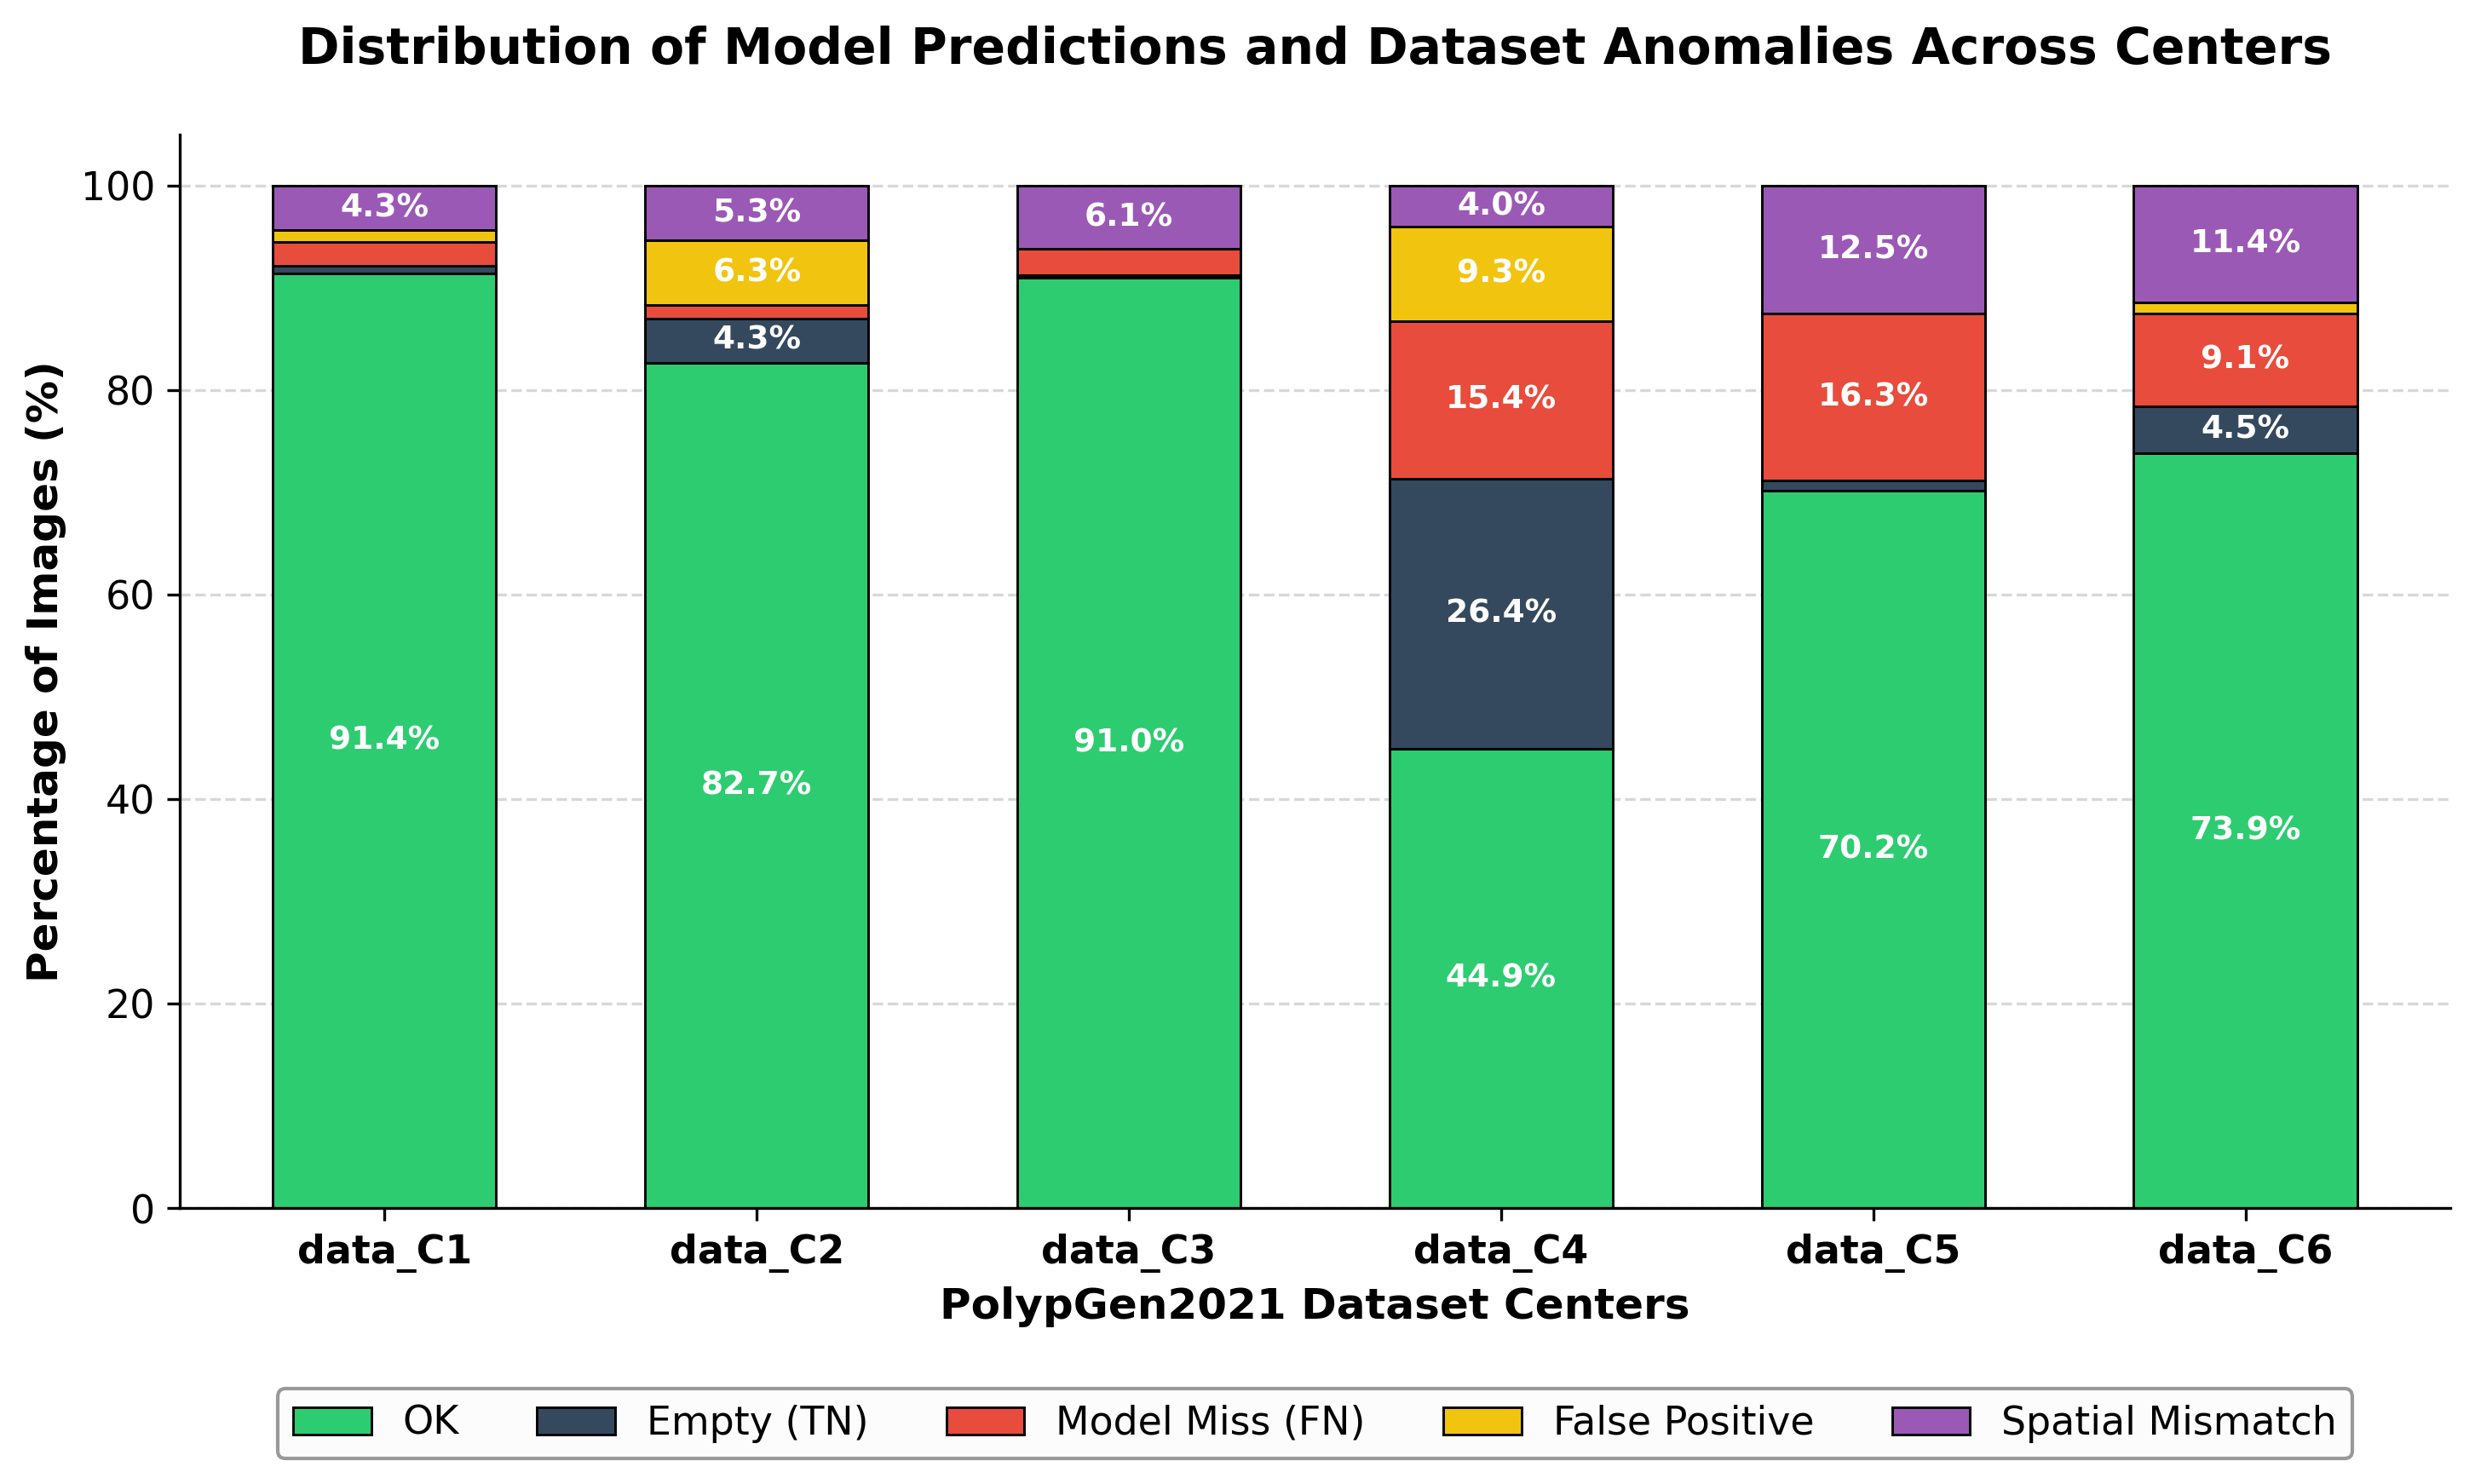

✅ Stacked Bar Chart successfully saved to: /mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/sequence-posimg/automated-mask-missmatch-report/dataset_audit_stacked_bar_chart.png


In [38]:
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# ১. অডিট রিপোর্টের ডাটা ইনপুট (আপনার মাস্টার রিপোর্ট অনুযায়ী)
data = {
    "Center": ["data_C1", "data_C2", "data_C3", "data_C4", "data_C5", "data_C6"],
    "OK": [234, 249, 415, 102, 146, 65],
    "Empty (TN)": [2, 13, 1, 60, 2, 4],
    "Model Miss (FN)": [6, 4, 12, 35, 34, 8],
    "False Positive": [3, 19, 0, 21, 0, 1],
    "Spatial Mismatch": [11, 16, 28, 9, 26, 10],
}

df = pd.DataFrame(data)
df.set_index("Center", inplace=True)

# ২. রিয়েল সংখ্যাগুলোকে ১০০% স্ট্যাকড বার চার্টের জন্য শতাংশে (Percentage) রূপান্তর
df_percentage = df.div(df.sum(axis=1), axis=0) * 100

# ৩. প্লট কনফিগারেশন (Scientific Paper Standard)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 11

# জার্নাল বা থিসিসের স্ট্যান্ডার্ড কালার প্যালেট (ক্লিন এবং ডিসেন্ট)
colors = ["#2ecc71", "#34495e", "#e74c3c", "#f1c40f", "#9b59b6"]
# OK (Green), Empty (Dark Gray), Miss (Red), FP (Yellow), Mismatch (Purple)

fig, ax = plt.subplots(figsize=(10, 6), dpi=300)  # High resolution for print

# ৪. স্ট্যাকড বার চার্ট ড্র করা
df_percentage.plot(
    kind="bar", stacked=True, color=colors, width=0.6, ax=ax, edgecolor="black", linewidth=0.7
)

# X-অক্ষের লেবেলগুলো সোজা রাখার জন্য
plt.xticks(rotation=0, fontweight="bold")

# ৫. বারগুলোর ভেতরে পারসেন্টেজ টেক্সট বসানো (অটোমেটেড লেবেলিং)
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if height > 3.5:  # শুধুমাত্র ৩.৫% এর চেয়ে বড় অংশগুলোতে টেক্সট দেখাবে (যাতে ওভারল্যাপ না হয়)
        ax.text(
            x + width / 2,
            y + height / 2,
            f"{height:.1f}%",
            ha="center",
            va="center",
            color="white" if p.get_facecolor()[:3] != (1.0, 0.768, 0.058) else "black",
            # ইয়েলো কালারের ওপর টেক্সট ব্ল্যাক হবে, বাকিগুলোতে হোয়াইট
            fontsize=9,
            fontweight="bold",
        )

# ৬. এক্সিস লেবেল এবং টাইটেল ফিক্স করা
ax.set_ylabel("Percentage of Images (%)", fontsize=12, fontweight="bold")
ax.set_xlabel("PolypGen2021 Dataset Centers", fontsize=12, fontweight="bold")
ax.set_title(
    "Distribution of Model Predictions and Dataset Anomalies Across Centers",
    fontsize=14,
    fontweight="bold",
    pad=20,
)

# ৭. লেজেন্ড (Legend) পেপারের ফরম্যাট অনুযায়ী বক্সের বাইরে নিচে সুন্দর করে বসানো
ax.legend(
    bbox_to_anchor=(0.5, -0.15),
    loc="upper center",
    ncol=5,
    frameon=True,
    facecolor="#fcfcfc",
    edgecolor="gray",
)

# ৮. চার্টের গ্রিড ও ফ্রেম ক্লিন করা
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_axisbelow(True)
ax.yaxis.grid(color="gray", linestyle="dashed", alpha=0.3)

plt.tight_layout()

# ৯. ইমেজ ফাইল হিসেবে সেভ করা
output_dir = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/outputs/sequence-posimg/automated-mask-missmatch-report/"
os.makedirs(output_dir, exist_ok=True)
output_path = os.path.join(output_dir, "dataset_audit_stacked_bar_chart.png")

plt.savefig(output_path, bbox_inches="tight", dpi=300)
plt.show()

print(f"✅ Stacked Bar Chart successfully saved to: {output_path}")